# F1 · Madde 2 — Federe model neden merkezi modelden zayıf? (teşhis, tohum 0)
**Profesörün notu:** *Federated modelin merkezi modele göre neden belirgin şekilde düşük performans gösterdiğini araştır ve
eşdeğer eğitim koşullarında yeniden karşılaştır.*

Ara dönemde (tohum 0): görülmemiş ANOMALY merkezi %47,0, FedAvg-IID %13,7, yalnız yerel %13,9. O protokolde
FedAvg 40 tur × 5 yerel epoch, Keras Adam her yerel eğitimde yeniden oluşturuluyordu; merkezi model 200 epoch eğitildi.

**Sınanan hipotezler (sonuç varsayılmaz, ölçülür):**

| | Hipotez | Bu defterdeki test |
|---|---|---|
| H1 | **Adım sayısı eşit değil.** Ara dönem karşılaştırması epoch sayısında eşitti (200 epoch), ama güncelleme adımında değil: 5 IID istemcide istemci başına ~4 yığın/epoch → 40×5 yerel epoch ≈ 800 adım; merkezi 200 epoch ≈ 3.400 adım. Ağırlık ortalaması adımları toplamaz. | merkezi model FedAvg-IID ile **aynı adım sayısında**; FedAvg aynı tur/epoch ama **yığın/K** ile (adım sayısı ≈ merkezi); FedAvg **yakınsama kuralına kadar** |
| H2 | **Adam durumu her turda sıfırlanıyor.** | K = 1 istemcide Adam korunur / sıfırlanır; yakınsamada korunur / sıfırlanır |
| H3 | **Non-IID istemci sapması (client drift).** | FedProx (μ = `cfg.fl_fedprox_mu`) |
| — | **Kod yolu kontrolü.** FL kodu K = 1 iken merkezi eğitime denk olmalı. | FL kodu K = 1 (Adam korunur) ↔ Keras merkezi |

**Eşdeğer eğitim koşulu (bu çalışmadaki tanım):** aynı model, optimizer (Adam), öğrenme oranı, yığın boyutu ve **aynı
yakınsama kuralı** (en iyi doğrulama kaybı 50 epoch'ta %0,5'ten az iyileşince dur; 40 epoch sabır; en fazla 1.500 epoch;
en iyi ağırlıklar geri yüklenir). FL'de bir tur = E yerel epoch sayılır. Doğrulama kaybı = istemcilerin normal-doğrulama
parçalarının birleşimindeki kayıp.

**Kalibrasyon:** *istemci başına* (her istemci kendi normal-kalibrasyon parçası; doğrudan uygulanabilir) ve *havuz skor*
(istemciler veri değil yalnız kalibrasyon **skorlarını** sunucuya gönderir; bu paylaşımın kabul edilebilir olması gerekir).

**Not:** Bu defter teşhis içindir (tek tohum). Sonuçlar F3'te 10 tohumla tekrarlanır; buradan kesin sonuç çıkarılmaz.

In [1]:
# ---- Kurulum (her defterde aynı): Drive'ı bağla, ortak kodu içe aktar ----
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
PROJECT_DIR = os.environ.get("TRUSTIDS_PROJECT", "/content/drive/MyDrive/TrustFed-TinyIDS-Final")
QUICK = os.environ.get("TRUSTIDS_QUICK", "0") == "1"   # hızlı mod YALNIZCA kodu test etmek içindir
# Devam modu: Colab oturumu kapanırsa, Drive'a kaydedilmiş tohumlar/adımlar atlanır ve kalan yerden devam edilir.
# Her şeyi baştan hesaplamak için: os.environ["TRUSTIDS_RESUME"] = "0"
RESUME = os.environ.get("TRUSTIDS_RESUME", "1") == "1"
sys.path.insert(0, PROJECT_DIR)

from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from trustids.config import Config
from trustids import utils

# Veri kümesi seçimi: varsayılan TON_IoT; ikinci veri kümesi için TRUSTIDS_CONFIG=edge_iiotset.json
CONFIG_NAME = os.environ.get("TRUSTIDS_CONFIG", "default.json")
CFG_PATH = Path(PROJECT_DIR) / "configs" / CONFIG_NAME
if CONFIG_NAME != "default.json" and not CFG_PATH.exists():
    raise FileNotFoundError(f"{CFG_PATH} bulunamadı: configs/ klasörünü de Drive'a yükleyin.")
cfg = Config.load(CFG_PATH) if CFG_PATH.exists() else Config(project_dir=PROJECT_DIR)
cfg.project_dir = PROJECT_DIR
if QUICK:
    cfg.train_seeds, cfg.validity_resplits, cfg.epochs = cfg.train_seeds[:2], 30, 15
    cfg.random_control_repeats, cfg.bootstrap_repeats = 10, 200
    cfg.lofo_seeds, cfg.fl_orig_rounds = cfg.lofo_seeds[:2], 3
    cfg.resolution_cal_windows, cfg.resolution_eval_windows = 600, 600
cfg.check()
ART = cfg.artifacts
FIG = Path(PROJECT_DIR) / cfg.figures_dir; FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("Proje klasörü:", PROJECT_DIR, "| hızlı mod:", QUICK, "| devam modu:", RESUME)
print("Drive'da kayıtlı ilerleme:", utils.progress(cfg))

Mounted at /content/drive
Proje klasörü: /content/drive/MyDrive/TrustFed-TinyIDS-Final | hızlı mod: False | devam modu: True
Drive'da kayıtlı ilerleme: {'01_hazirlanan_veri': True, '02_tohumlar_tamam': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '02_oznitelik_karsilastirma_tohumlari': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '03_kararlar': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '04b_host_eslesmesi': False}


In [2]:
import math, tensorflow as tf
from trustids import data as D, models as M, conformal as C, fl as FL
P = D.load_prepared(ART / "prepared"); X = P["X"]
FNAMES = P["preprocessor"].feature_names_
CHOSEN = utils.load_json(ART / "ae_selection.json")["chosen"]; spec = cfg.ae_variants[CHOSEN]
SEED, K, E_LOC = cfg.train_seeds[0], cfg.fl_clients, cfg.fl_local_epochs
DIAG = ART / "fl_diag"; DIAG.mkdir(exist_ok=True)
FP = utils.fingerprint(cfg, ["fl_clients", "fl_scenarios", "fl_orig_rounds", "fl_local_epochs", "fl_fedprox_mu"])
RUN = utils.new_run_dir(Path(PROJECT_DIR) / cfg.runs_dir, "final_F1_fl_teshis")
utils.save_json(utils.environment_info(), RUN / "environment.json"); cfg.save(RUN / "config_used.json")
d_in = X["benign_train"].shape[1]
def build(): return M.build_autoencoder(d_in, spec["hidden"], spec["dropout"], cfg.learning_rate)
CAT = {sp: FL.service_categories(X[sp], FNAMES) for sp in ["benign_train", "benign_val", "benign_cal", "benign_test"]}
PARTS = {s: FL.partition(CAT, K, s, SEED) for s in cfg.fl_scenarios}
SIZES = pd.DataFrame([{"senaryo": s, "istemci": k, **{sp: len(PARTS[s][sp][k]) for sp in CAT}}
                      for s in cfg.fl_scenarios for k in range(K)])
SIZES.to_csv(RUN / "F1_istemci_boyutlari.csv", index=False)
assert (SIZES[["benign_train", "benign_val", "benign_cal", "benign_test"]] > 0).all().all(), "boş istemci parçası var"
print("AE:", CHOSEN, "| tohum", SEED, "| istemci", K, "| yerel epoch", E_LOC, "| parmak izi", FP, "| sonuç klasörü:", RUN)
SIZES.pivot(index="istemci", columns="senaryo", values="benign_train")

AE: ae_32_16_8 | tohum 0 | istemci 5 | yerel epoch 5 | parmak izi feda4e8c23b8 | sonuç klasörü: /content/drive/MyDrive/TrustFed-TinyIDS-Final/runs/20261110-222358_final_F1_fl_teshis


senaryo,Dirichlet=0.1,Dirichlet=1.0,IID
istemci,,,
0,865,3101,1673
1,1843,2050,1674
2,5269,1264,1673
3,201,128,1674
4,192,1827,1676


## H1 · Güncelleme adımı hesabı (eğitimden önce, yalnız aritmetik)

In [3]:
bs, n_tr = cfg.batch_size, len(X["benign_train"])
c_ep = math.ceil(n_tr / bs)
rows = [{"eğitim": f"merkezi, {cfg.fl_orig_rounds * E_LOC} epoch (ara dönem)", "güncelleme_adımı": c_ep * cfg.fl_orig_rounds * E_LOC}]
for s in cfg.fl_scenarios:
    st = [cfg.fl_orig_rounds * E_LOC * math.ceil(len(p) / bs) for p in PARTS[s]["benign_train"]]
    rows.append({"eğitim": f"FedAvg {s}, {cfg.fl_orig_rounds} tur × {E_LOC} yerel epoch — istemci başına ortalama",
                 "güncelleme_adımı": float(np.mean(st))})
STEPS = pd.DataFrame(rows); STEPS.to_csv(RUN / "F1_adim_hesabi.csv", index=False)
EQ_EPOCHS = max(1, int(round(STEPS.iloc[1]["güncelleme_adımı"] / c_ep)))
print("merkezi epoch başına adım:", c_ep, "| FedAvg-IID istemci adımına eşit merkezi epoch:", EQ_EPOCHS)
STEPS

merkezi epoch başına adım: 17 | FedAvg-IID istemci adımına eşit merkezi epoch: 47


,eğitim,güncelleme_adımı
0,"merkezi, 200 epoch (ara dönem)",3400.0
1,"FedAvg IID, 40 tur × 5 yerel epoch — istemci b...",800.0
2,"FedAvg Dirichlet=1.0, 40 tur × 5 yerel epoch —...",800.0
3,"FedAvg Dirichlet=0.1, 40 tur × 5 yerel epoch —...",760.0


## Eğitimler (her model Drive'a kaydedilir; oturum kapanırsa devam modunda atlanır)

In [4]:
ALL = np.arange(n_tr)
def cached(key, train_fn):
    mf, jf = DIAG / f"{key}_{FP}.keras", DIAG / f"{key}_{FP}.json"
    if RESUME and mf.exists() and jf.exists():
        print("kayıtlı, atlanıyor:", key); return tf.keras.models.load_model(mf, compile=False), utils.load_json(jf)
    print("eğitiliyor:", key, flush=True)
    m, info = train_fn(); m.save(mf); utils.save_json(info, jf); return m, info

def keras_fixed(epochs):
    def f():
        utils.set_seed(SEED); m = build()
        m.fit(X["benign_train"], X["benign_train"], epochs=epochs, batch_size=bs, shuffle=True, verbose=0)
        return m, {"epochs_equivalent": epochs, "stopped_by": "fixed_epochs", "local_steps_mean": epochs * c_ep, "comm_MB": 0.0}
    return f

def keras_conv():
    p = ART / "models" / f"ae_seed{SEED}.keras"
    if p.exists():                                   # 02 defterinde aynı kuralla eğitilen ana model
        tr = utils.load_json(ART / "training" / f"seed{SEED}.json")
        return tf.keras.models.load_model(p, compile=False), {"epochs_equivalent": tr["epoch"], "stopped_by": tr["durma_nedeni"],
                                                              "local_steps_mean": tr["epoch"] * c_ep, "comm_MB": 0.0}
    utils.set_seed(SEED); m = build()
    h = M.train_autoencoder(m, X["benign_train"], X["benign_val"], cfg.epochs, bs, cfg.patience,
                            conv_window=cfg.conv_window, conv_rel_tol=cfg.conv_rel_tol)
    return m, {"epochs_equivalent": h["epochs_run"], "stopped_by": h["stopped_by"], "local_steps_mean": h["epochs_run"] * c_ep, "comm_MB": 0.0}

def fl_run(parts, rounds, opt_state, mu, Xtr=None, Xval=None, seed=SEED):
    def f():
        return FL.train_federated(build, X["benign_train"] if Xtr is None else Xtr, parts,
                                  X["benign_val"] if Xval is None else Xval, rounds=rounds, local_epochs=E_LOC,
                                  lr=cfg.learning_rate, batch_size=bs, seed=seed, optimizer_state=opt_state, mu=mu,
                                  conv_window=cfg.conv_window, conv_rel_tol=cfg.conv_rel_tol, patience=cfg.patience,
                                  epoch_cap=cfg.epochs, verbose=True)
    return f

MODELS, INFO = {}, {}
def add(key, desc, scen, fn):
    m, info = cached(key, fn); MODELS[key] = m; INFO[key] = {**info, "açıklama": desc, "senaryo": scen}

R0 = cfg.fl_orig_rounds
add("M_yakinsama", "Merkezi, yakınsama kuralı (ana model)", "merkezi", keras_conv)
add("M_200", f"Merkezi, {R0 * E_LOC} epoch (ara dönem karşılaştırması)", "merkezi", keras_fixed(R0 * E_LOC))
add("M_esit_adim", f"Merkezi, {EQ_EPOCHS} epoch (= FedAvg-IID istemci adım sayısı)", "merkezi", keras_fixed(EQ_EPOCHS))
add("M_fl_kodu", "Merkezi, FL kodu (K=1), yakınsama, Adam korunur", "merkezi", fl_run([ALL], None, "persistent", 0.0))
add("K1_orijinal_kalici", f"FL kodu K=1, {R0}×{E_LOC}, Adam korunur (≈ M_200 olmalı)", "merkezi", fl_run([ALL], R0, "persistent", 0.0))
add("K1_orijinal_reset", f"FL kodu K=1, {R0}×{E_LOC}, Adam her tur sıfırlanır (H2 tek başına)", "merkezi", fl_run([ALL], R0, "reset", 0.0))
for s in cfg.fl_scenarios:
    for prot, pz in FL.PROTOCOLS.items():
        add(f"FL_{s.replace('=', '')}_{prot}", f"{s}: {pz['aciklama']}", s,
            lambda s=s, prot=prot: FL.run_protocol(prot, cfg, build, X["benign_train"], PARTS[s]["benign_train"], X["benign_val"], SEED, verbose=True))
LOCAL = {}
for s in [cfg.fl_scenarios[0], cfg.fl_scenarios[-1]]:
    ms = []
    for k in range(K):
        tr, va = PARTS[s]["benign_train"][k], PARTS[s]["benign_val"][k]
        m, info = cached(f"YEREL_{s.replace('=', '')}_k{k}",
                         fl_run([np.arange(len(tr))], None, "persistent", 0.0, Xtr=X["benign_train"][tr], Xval=X["benign_val"][va], seed=SEED + k))
        ms.append(m); INFO[f"YEREL_{s.replace('=', '')}_k{k}"] = {**info, "açıklama": f"yalnız yerel {s}, istemci {k}", "senaryo": s}
    LOCAL[s] = ms
print("tüm eğitimler tamam")

eğitiliyor: M_yakinsama
eğitiliyor: M_200
eğitiliyor: M_esit_adim
eğitiliyor: M_fl_kodu
  tur 10: doğrulama kaybı 0.002915 (en iyi 0.002915)
  tur 20: doğrulama kaybı 0.001774 (en iyi 0.001774)
  tur 30: doğrulama kaybı 0.001415 (en iyi 0.001415)
  tur 40: doğrulama kaybı 0.001243 (en iyi 0.001243)
  tur 50: doğrulama kaybı 0.001133 (en iyi 0.001133)
  tur 60: doğrulama kaybı 0.001070 (en iyi 0.001070)
  tur 70: doğrulama kaybı 0.001041 (en iyi 0.001041)
  tur 80: doğrulama kaybı 0.001006 (en iyi 0.001006)
  tur 90: doğrulama kaybı 0.000982 (en iyi 0.000982)
  tur 100: doğrulama kaybı 0.000967 (en iyi 0.000965)
  tur 110: doğrulama kaybı 0.000947 (en iyi 0.000946)
  tur 120: doğrulama kaybı 0.000939 (en iyi 0.000926)
  tur 130: doğrulama kaybı 0.000914 (en iyi 0.000913)
  tur 140: doğrulama kaybı 0.000906 (en iyi 0.000901)
  tur 150: doğrulama kaybı 0.000889 (en iyi 0.000886)
  tur 160: doğrulama kaybı 0.000882 (en iyi 0.000871)
  tur 170: doğrulama kaybı 0.000870 (en iyi 0.000864)
  t

## Değerlendirme: her model × istemci bölmesi × kalibrasyon

In [5]:
ROWS = []
for key, m in MODELS.items():
    scen = cfg.fl_scenarios if INFO[key]["senaryo"] == "merkezi" else [INFO[key]["senaryo"]]
    sc = {sp: M.ae_score(m, X[sp]) for sp in ["benign_cal", "benign_test", "dev_test", "heldout_test"]}
    for s in scen:
        for r in FL.evaluate(lambda k, sp, sc=sc: sc[sp], PARTS[s], X, cfg, SEED):
            ROWS.append({"model": key, "açıklama": INFO[key]["açıklama"], "istemci_bölmesi": s, **r})
for s, ms in LOCAL.items():
    for r in FL.evaluate(lambda k, sp, ms=ms: M.ae_score(ms[k], X[sp]), PARTS[s], X, cfg, SEED, per_client_models=True):
        ROWS.append({"model": f"YEREL_{s.replace('=', '')}", "açıklama": f"Yalnız yerel eğitim ({s}), yakınsama", "istemci_bölmesi": s, **r})
RES = pd.DataFrame(ROWS); RES.to_csv(RUN / "F1_sonuclar.csv", index=False)
TR = pd.DataFrame([{"model": k, **{a: b for a, b in i.items() if a != "val_hist"}} for k, i in INFO.items()])
TR.to_csv(RUN / "F1_egitim_bilgisi.csv", index=False)
display(TR[["model", "açıklama", "stopped_by", "epochs_equivalent", "local_steps_mean", "comm_MB"]].round(2))
RES[RES["kalibrasyon"] == "havuz skor"][["model", "istemci_bölmesi", "istemci_FPR_ort", "istemci_FPR_en_kötü",
     "görülmemiş_ANOMALY", "görülmemiş_UNCERTAIN", "bilinen_ANOMALY", "f1_görülmemiş", "selective_risk"]].round(4)

,model,açıklama,stopped_by,epochs_equivalent,local_steps_mean,comm_MB
0,M_yakinsama,"Merkezi, yakınsama kuralı (ana model)",relative_plateau,1274,21658.0,0.00
1,M_200,"Merkezi, 200 epoch (ara dönem karşılaştırması)",fixed_epochs,200,3400.0,0.00
2,M_esit_adim,"Merkezi, 47 epoch (= FedAvg-IID istemci adım s...",fixed_epochs,47,799.0,0.00
3,M_fl_kodu,"Merkezi, FL kodu (K=1), yakınsama, Adam korunur",early_stopping,980,16660.0,7.57
4,K1_orijinal_kalici,"FL kodu K=1, 40×5, Adam korunur (≈ M_200 olmalı)",fixed_rounds,200,3400.0,1.55
5,K1_orijinal_reset,"FL kodu K=1, 40×5, Adam her tur sıfırlanır (H2...",fixed_rounds,200,3400.0,1.55
6,FL_IID_orijinal,IID: ara dönem protokolü: 40 tur x 5 yerel epo...,fixed_rounds,200,800.0,7.73
7,FL_IID_orijinal_kucuk_yigin,"IID: ara dönem protokolü, ama yerel yığın = yı...",fixed_rounds,200,3400.0,7.73
8,FL_IID_yakinsama_reset,"IID: yakınsama kuralına kadar, Adam her turda ...",epoch_cap,1500,6000.0,57.95
9,FL_IID_yakinsama_kalici,"IID: yakınsama kuralına kadar, her istemci Ada...",epoch_cap,1500,6000.0,57.95


,model,istemci_bölmesi,istemci_FPR_ort,istemci_FPR_en_kötü,görülmemiş_ANOMALY,görülmemiş_UNCERTAIN,bilinen_ANOMALY,f1_görülmemiş,selective_risk
1,M_yakinsama,IID,0.0075,0.0120,0.4892,0.3552,0.1843,0.6567,0.6116
3,M_yakinsama,Dirichlet=1.0,0.0090,0.0175,0.4892,0.3552,0.1843,0.6567,0.6118
5,M_yakinsama,Dirichlet=0.1,0.0084,0.0241,0.4892,0.3552,0.1843,0.6567,0.6121
7,M_200,IID,0.0075,0.0105,0.4723,0.2940,0.1600,0.6413,0.6427
9,M_200,Dirichlet=1.0,0.0093,0.0175,0.4723,0.2940,0.1600,0.6413,0.6428
11,M_200,Dirichlet=0.1,0.0088,0.0267,0.4723,0.2940,0.1600,0.6413,0.6432
13,M_esit_adim,IID,0.0066,0.0090,0.1494,0.5284,0.0267,0.2598,0.8936
15,M_esit_adim,Dirichlet=1.0,0.0086,0.0175,0.1494,0.5284,0.0267,0.2598,0.8938
17,M_esit_adim,Dirichlet=0.1,0.0080,0.0267,0.1494,0.5284,0.0267,0.2598,0.8943
19,M_fl_kodu,IID,0.0087,0.0119,0.4822,0.3657,0.2067,0.6504,0.5996


In [6]:
RES[RES["kalibrasyon"] == "istemci başına"][["model", "istemci_bölmesi", "en_küçük_n_cal", "istemci_FPR_ort", "istemci_FPR_en_kötü",
     "görülmemiş_ANOMALY", "görülmemiş_UNCERTAIN", "bilinen_ANOMALY", "selective_risk"]].round(4)

,model,istemci_bölmesi,en_küçük_n_cal,istemci_FPR_ort,istemci_FPR_en_kötü,görülmemiş_ANOMALY,görülmemiş_UNCERTAIN,bilinen_ANOMALY,selective_risk
0,M_yakinsama,IID,668,0.0066,0.0120,0.4465,0.3968,0.1849,0.6248
2,M_yakinsama,Dirichlet=1.0,57,0.0061,0.0110,0.3586,0.3510,0.1816,0.6861
4,M_yakinsama,Dirichlet=0.1,78,0.0030,0.0094,0.2088,0.6006,0.1086,0.8065
6,M_200,IID,668,0.0057,0.0120,0.3607,0.4206,0.1206,0.7134
8,M_200,Dirichlet=1.0,57,0.0045,0.0089,0.3304,0.3209,0.1149,0.7466
10,M_200,Dirichlet=0.1,78,0.0026,0.0080,0.1905,0.5678,0.0561,0.8452
12,M_esit_adim,IID,668,0.0066,0.0150,0.1535,0.5245,0.0233,0.8941
14,M_esit_adim,Dirichlet=1.0,57,0.0055,0.0130,0.1809,0.3606,0.0225,0.8920
16,M_esit_adim,Dirichlet=0.1,78,0.0045,0.0107,0.1555,0.5089,0.0249,0.8937
18,M_fl_kodu,IID,668,0.0063,0.0120,0.3645,0.4726,0.1230,0.7073


## Hipotez tablosu (tohum 0; yalnız fark gösterilir, sonuç F3'teki 10 tohumla verilir)

In [7]:
def v(model, scen, cal="havuz skor", col="görülmemiş_ANOMALY"):
    q = RES[(RES["model"] == model) & (RES["istemci_bölmesi"] == scen) & (RES["kalibrasyon"] == cal)]
    return float(q[col].iloc[0]) if len(q) else np.nan
s0 = cfg.fl_scenarios[0]; t0 = s0.replace("=", "")
H = [("Ara dönem farkı: merkezi 200 epoch − FedAvg-IID orijinal", v("M_200", s0), v(f"FL_{t0}_orijinal", s0)),
     ("H1: merkezi (FedAvg-IID adım sayısında) − FedAvg-IID orijinal", v("M_esit_adim", s0), v(f"FL_{t0}_orijinal", s0)),
     ("H1: FedAvg-IID küçük yığın (≈ merkezi adım sayısı) − FedAvg-IID orijinal", v(f"FL_{t0}_orijinal_kucuk_yigin", s0), v(f"FL_{t0}_orijinal", s0)),
     ("H1: merkezi 200 epoch − FedAvg-IID küçük yığın", v("M_200", s0), v(f"FL_{t0}_orijinal_kucuk_yigin", s0)),
     ("Kod yolu: Keras merkezi 200 epoch − FL kodu K=1 Adam korunur", v("M_200", s0), v("K1_orijinal_kalici", s0)),
     ("H2: K=1 Adam korunur − K=1 Adam sıfırlanır", v("K1_orijinal_kalici", s0), v("K1_orijinal_reset", s0)),
     ("Kod yolu: merkezi yakınsama (Keras) − merkezi yakınsama (FL kodu)", v("M_yakinsama", s0), v("M_fl_kodu", s0))]
for s in cfg.fl_scenarios:
    t = s.replace("=", "")
    H += [(f"{s}: FedAvg yakınsama Adam korunur − FedAvg orijinal", v(f"FL_{t}_yakinsama_kalici", s), v(f"FL_{t}_orijinal", s)),
          (f"{s}: FedAvg yakınsama Adam korunur − Adam sıfırlanır (H2)", v(f"FL_{t}_yakinsama_kalici", s), v(f"FL_{t}_yakinsama_reset", s)),
          (f"{s}: FedProx − FedAvg yakınsama (H3)", v(f"FL_{t}_fedprox_kalici", s), v(f"FL_{t}_yakinsama_kalici", s)),
          (f"{s}: EŞDEĞER KOŞUL merkezi yakınsama − FedAvg yakınsama Adam korunur", v("M_yakinsama", s), v(f"FL_{t}_yakinsama_kalici", s))]
HT = pd.DataFrame(H, columns=["karşılaştırma (görülmemiş ANOMALY, havuz skor kalibrasyonu)", "a", "b"])
HT["a − b (puan)"] = 100 * (HT["a"] - HT["b"])
HT.to_csv(RUN / "F1_hipotez_tablosu.csv", index=False); HT.round(4)

,"karşılaştırma (görülmemiş ANOMALY, havuz skor kalibrasyonu)",a,b,a − b (puan)
0,Ara dönem farkı: merkezi 200 epoch − FedAvg-II...,0.4723,0.0053,46.6953
1,H1: merkezi (FedAvg-IID adım sayısında) − FedA...,0.1494,0.0053,14.4024
2,H1: FedAvg-IID küçük yığın (≈ merkezi adım say...,0.4840,0.0053,47.8684
3,H1: merkezi 200 epoch − FedAvg-IID küçük yığın,0.4723,0.4840,-1.1731
4,Kod yolu: Keras merkezi 200 epoch − FL kodu K=...,0.4723,0.2408,23.1486
5,H2: K=1 Adam korunur − K=1 Adam sıfırlanır,0.2408,0.4192,-17.8381
6,Kod yolu: merkezi yakınsama (Keras) − merkezi ...,0.4892,0.4822,0.6913
7,IID: FedAvg yakınsama Adam korunur − FedAvg or...,0.4769,0.0053,47.1562
8,IID: FedAvg yakınsama Adam korunur − Adam sıfı...,0.4769,0.1721,30.4808
9,IID: FedProx − FedAvg yakınsama (H3),0.1721,0.4769,-30.4808


Sonuçlar: /content/drive/MyDrive/TrustFed-TinyIDS-Final/runs/20261110-222358_final_F1_fl_teshis


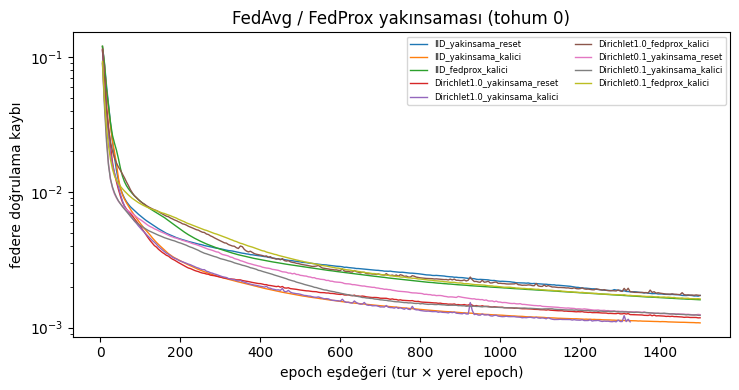

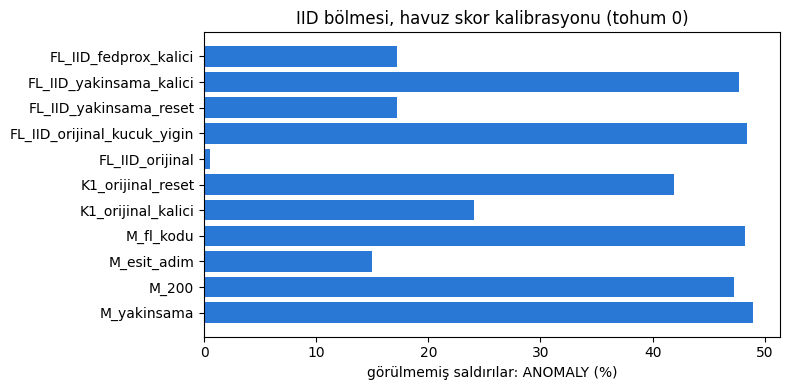

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for key, i in INFO.items():
    if i.get("val_hist") and key.startswith("FL_"):
        e = np.arange(1, len(i["val_hist"]) + 1) * E_LOC
        ax.plot(e, i["val_hist"], lw=1, label=key.replace("FL_", ""))
ax.set_yscale("log"); ax.set_xlabel("epoch eşdeğeri (tur × yerel epoch)"); ax.set_ylabel("federe doğrulama kaybı")
ax.set_title(f"FedAvg / FedProx yakınsaması (tohum {SEED})"); ax.legend(fontsize=6, ncol=2)
fig.tight_layout(); fig.savefig(RUN / "F1_yakinsama.png", dpi=150)
sub = RES[(RES["kalibrasyon"] == "havuz skor") & (RES["istemci_bölmesi"] == s0)]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(sub["model"], 100 * sub["görülmemiş_ANOMALY"], color="#2a78d6")
ax.set_xlabel("görülmemiş saldırılar: ANOMALY (%)"); ax.set_title(f"{s0} bölmesi, havuz skor kalibrasyonu (tohum {SEED})")
fig.tight_layout(); fig.savefig(RUN / "F1_gorulmemis_anomaly.png", dpi=150)
print("Sonuçlar:", RUN)

In [9]:
# Colab: Drive'a yazılan tüm dosyaların kaydedildiğinden emin ol (oturumu kapatmadan önce mutlaka çalıştırın)
print("Kaydedilen ilerleme:", utils.progress(cfg))
if IN_COLAB:
    drive.flush_and_unmount()
    print("Drive kaydedildi ve ayrıldı. Sonraki defter Drive'ı yeniden bağlar.")

Kaydedilen ilerleme: {'01_hazirlanan_veri': True, '02_tohumlar_tamam': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '02_oznitelik_karsilastirma_tohumlari': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '03_kararlar': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '04b_host_eslesmesi': False}
Drive kaydedildi ve ayrıldı. Sonraki defter Drive'ı yeniden bağlar.


In [10]:
from google.colab import runtime
runtime.unassign()